In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from matplotlib.gridspec import GridSpec

### Import data observation (Table S7- Raw counts) and write function for Bottleneck size (Abel et al)

In [2]:
# ---- load Table S7 ----
df = pd.read_csv('Table-S7-sgRNA-Raw-Counts.csv', header=1)
df = df.dropna(subset=["Geneid"]).copy()

### Compute bottleneck size at 24 hpi

In [3]:
# in vivo doubling time used in Liu et al. supplement: 108 min
"The doubling time of S. pneumoniae used in the calculation as 108 minutes."
"This was based on a previous Tn-seq study (van Opijnen and Camilli, 2012)"
g = (24 * 60) / 108  # 13.333...

# time-0 columns for the 24 h pneumonia block
pre_cols = ["Pre1", "Pre2"]  # pooled
# --------------------------------------------

# Insert mouse index: with/ without dox
def mouse_index(colname: str) -> int:
    m = re.search(r"(\d+)$", str(colname))
    return int(m.group(1)) if m else 10**9

# Function to compute bottleneck size
def compute_Nb_for_sample(df_counts: pd.DataFrame, f0: np.ndarray, S0: float, sample_col: str, g: float) -> float:
    cs = df_counts[sample_col].astype(float).to_numpy()
    Ss = float(cs.sum())
    fs = cs / Ss

    # Must filter sgRNAs that are present at time 0 (to avoid division by zero)
    mask = f0 > 0
    F = np.mean(((fs[mask] - f0[mask]) ** 2) / (f0[mask] * (1.0 - f0[mask])))
    denom = F - (1.0 / S0) - (1.0 / Ss)
    return np.nan if denom <= 0 else (g / denom)

In [4]:
# Pre1 = inoculum for no-dox mice; Pre2 = inoculum for +dox mice
pre_no  = "Pre1"
pre_dox = "Pre2"

# ---- compute time-0 frequencies f0 separately ----
c0_no  = df[pre_no].fillna(0).astype(float).to_numpy()
S0_no  = float(np.sum(c0_no))
f0_no  = c0_no / S0_no

c0_dox = df[pre_dox].fillna(0).astype(float).to_numpy()
S0_dox = float(np.sum(c0_dox))
f0_dox = c0_dox / S0_dox

# ---- pick 24 h pneumonia mouse columns (NoDox and +Dox) ----
no_cols  = sorted([c for c in df.columns if re.fullmatch(r"Mice_noDox_\d+",  str(c))], key=mouse_index)
dox_cols = sorted([c for c in df.columns if re.fullmatch(r"Mice_plusDox_\d+", str(c))], key=mouse_index)

labels = [f"#{mouse_index(c)}" for c in no_cols] + [f"#{mouse_index(c)}+dox" for c in dox_cols]

# ---- compute Nb per sample with the correct inoculum ----
Nb_no  = np.array([compute_Nb_for_sample(df, f0_no,  S0_no,  c, g) for c in no_cols], dtype=float)
Nb_dox = np.array([compute_Nb_for_sample(df, f0_dox, S0_dox, c, g) for c in dox_cols], dtype=float)

Nb = np.concatenate([Nb_no, Nb_dox])

In [5]:
#export bottleneck size as a file csv
out = pd.DataFrame({"label": labels, "Nb_bottleneck_size": Nb})
out.to_csv("Abel_Nb_24hpi.csv", index=False)

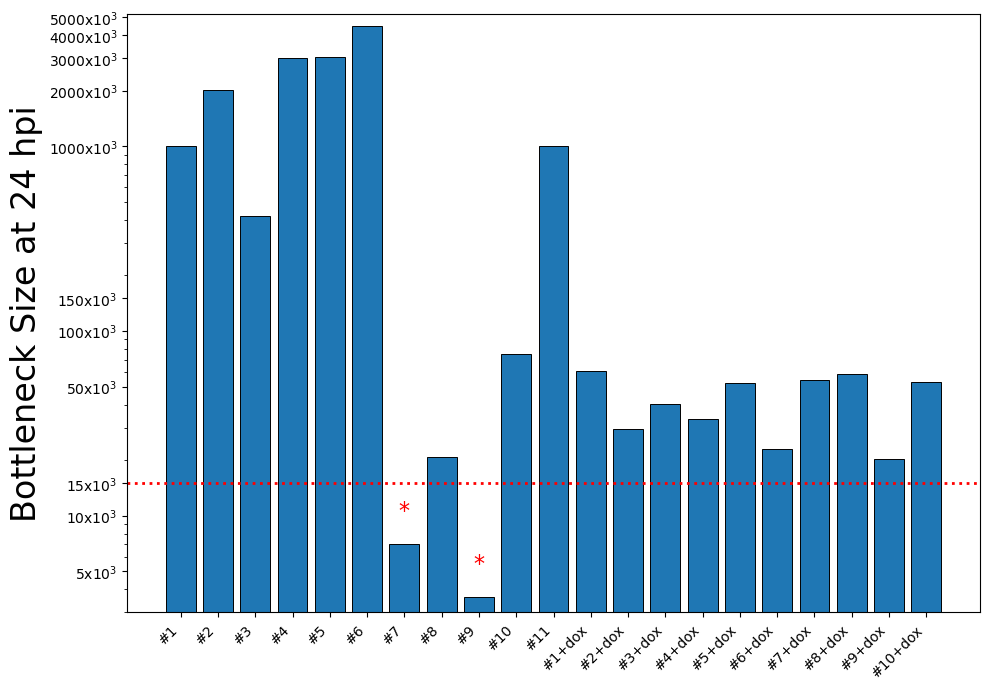

In [6]:
# ---- Figure 4B style plot ----
K = df.shape[0]                # number of sgRNAs (should be 1499)
threshold = 10 * K             # red dotted line at 10x diversity

x = np.arange(len(Nb))
plt.figure(figsize=(10, 7))
plt.bar(x, Nb, edgecolor="black", linewidth=0.7)

plt.yscale("log")
plt.ylabel("Bottleneck Size at 24 hpi", fontsize = 24)

yticks = [5e3, 1e4, 1.5e4, 5e4, 1e5, 1.5e5, 1e6, 2e6, 3e6, 4e6, 5e6]
plt.yticks(yticks, [f"{int(t/1000)}x10$^3$" for t in yticks])

plt.axhline(threshold, color="red", linestyle=":", linewidth=2)

plt.xticks(x, labels, rotation=45, ha="right")

# red asterisks for bars below the 10x diversity line (as in the paper figure)
for xi, yi in zip(x, Nb):
    if np.isfinite(yi) and yi < threshold:
        plt.text(xi, yi * 1.3, "*", color="red", ha="center", va="bottom", fontsize=16)

plt.ylim(3e3, 5.2e6)
plt.tight_layout()
plt.show()

# optionally save
# plt.savefig("Fig4B_like_24hpi_bottleneck.png", dpi=200)

### Compute bottleneck size at 48 hpi

In [7]:
df48 = pd.read_csv("df_48hpi.csv")
pre48 = pd.read_csv("pre48.csv")

# time-0 inoculum is condition-specific:
#   Pre1 = inoculum for no-dox mice
#   Pre2 = inoculum for +dox mice
c0_no  = pre48["Pre1"].fillna(0).astype(float).to_numpy()
S0_no  = float(np.sum(c0_no))
f0_no  = c0_no / S0_no
mask0_no = (f0_no > 0) & (f0_no < 1) & np.isfinite(f0_no)

c0_dox = pre48["Pre2"].fillna(0).astype(float).to_numpy()
S0_dox = float(np.sum(c0_dox))
f0_dox = c0_dox / S0_dox
mask0_dox = (f0_dox > 0) & (f0_dox < 1) & np.isfinite(f0_dox)

# generations at 48h using 108 min doubling time
g = (48 * 60) / 108  # 26.666...

In [8]:
#function computing bottleneck Abel
def parse(col: str):
    m = re.match(r"Mice_(noDox|Dox)-(\d+)-(Blood|Lung)$", str(col))
    if not m:
        return None
    return m.group(1), int(m.group(2)), m.group(3).lower()

def compute_Nb_from_counts(counts: np.ndarray, f0: np.ndarray, S0: float, mask0: np.ndarray, g: float) -> float:
    cs = np.nan_to_num(counts.astype(float), nan=0.0)
    Ss = float(np.sum(cs))
    if Ss <= 0 or S0 <= 0:
        return np.nan
    fs = cs / Ss

    denom_in = f0[mask0] * (1.0 - f0[mask0])
    ok = denom_in > 0
    if not np.any(ok):
        return np.nan

    F = np.mean(((fs[mask0][ok] - f0[mask0][ok]) ** 2) / denom_in[ok])
    denom = F - (1.0 / S0) - (1.0 / Ss)
    return np.nan if denom <= 0 else (g / denom)

In [9]:
# compute Nb per column (match inoculum to condition)
nb_map = {}
for col in df48.columns:
    key = parse(col)
    if key is None:
        continue

    grp, mouse, tissue = key
    if grp == "noDox":
        nb_map[key] = compute_Nb_from_counts(df48[col].to_numpy(), f0_no, S0_no, mask0_no, g)
    else:  # grp == "Dox"
        nb_map[key] = compute_Nb_from_counts(df48[col].to_numpy(), f0_dox, S0_dox, mask0_dox, g)

# assemble + export
blood_keys = [parse(c) for c in df48.columns if str(c).endswith("-Blood") and parse(c) is not None]
samples = sorted({(grp, mouse) for (grp, mouse, _) in blood_keys},
                 key=lambda x: (0 if x[0] == "noDox" else 1, x[1]))

rows = []
for grp, mouse in samples:
    rows.append({
        "group": grp,
        "mouse": mouse,
        "label": f"#{mouse}" + ("" if grp == "noDox" else "+dox"),
        "lung":  nb_map.get((grp, mouse, "lung"),  np.nan),
        "blood": nb_map.get((grp, mouse, "blood"), np.nan),
    })
res = pd.DataFrame(rows)
res["max_nb"] = res[["lung", "blood"]].max(axis=1, skipna=True)

res.to_csv("Abel-Nb_48hpi.csv", index=False)
# split outliers to right panel (like Fig 4C)
y_main_max = 400
outliers = res[res["max_nb"] > y_main_max].reset_index(drop=True)
main     = res[res["max_nb"] <= y_main_max].reset_index(drop=True)

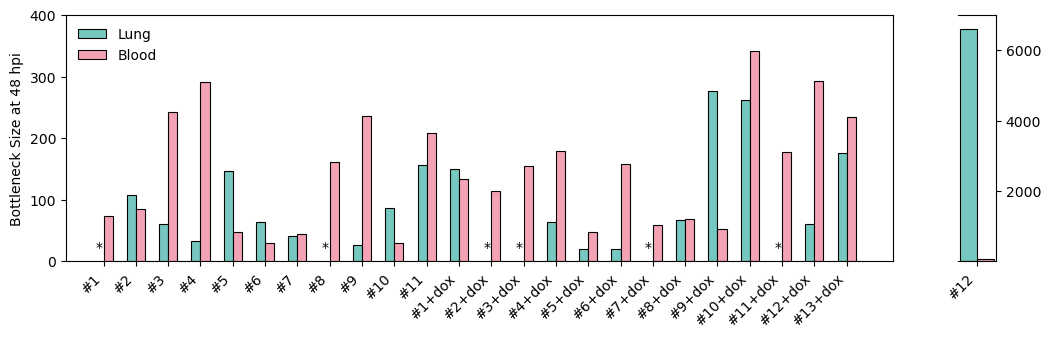

In [12]:
# ---- plot ----
bar_w = 0.28
fig = plt.figure(figsize=(12, 3.2))
gs = GridSpec(1, 2, width_ratios=[22, 1], wspace=0.15)

ax = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])

def bars(axh, dfblock, ylim, show_ylabel=False):
    x = np.arange(len(dfblock))
    lung_vals  = dfblock["lung"].to_numpy()
    blood_vals = dfblock["blood"].to_numpy()

    # keep NaNs as NaNs so bars are not drawn
    lung_h  = np.where(np.isfinite(lung_vals),  lung_vals,  np.nan)
    blood_h = np.where(np.isfinite(blood_vals), blood_vals, np.nan)

    axh.bar(x - bar_w/2, lung_h,  width=bar_w, label="Lung",
            color="#76c7c0", edgecolor="black", linewidth=0.8)
    axh.bar(x + bar_w/2, blood_h, width=bar_w, label="Blood",
            color="#f4a3b5", edgecolor="black", linewidth=0.8)

    axh.set_ylim(*ylim)
    axh.set_xticks(x)
    axh.set_xticklabels(dfblock["label"].tolist(), rotation=45, ha="right")

    if show_ylabel:
        axh.set_ylabel("Bottleneck Size at 48 hpi")

    # asterisks where lung is missing
    for xi, lv in zip(x, lung_vals):
        if not np.isfinite(lv):
            axh.text(xi - bar_w/2, ylim[0] + (ylim[1]-ylim[0]) * 0.03, "*",
                     ha="center", va="bottom", fontsize=10, color="black")

bars(ax, main, ylim=(0, y_main_max), show_ylabel=True)
ax.set_yticks([0, 100, 200, 300, 400])

if len(outliers) == 0:
    ax2.axis("off")
else:
    y2_max = max(7000, float(np.nanmax(outliers[["lung","blood"]].to_numpy())) * 1.05)
    bars(ax2, outliers, ylim=(0, y2_max), show_ylabel=False)
    ax2.yaxis.tick_right()
    ax2.spines["left"].set_visible(False)
    ax2.set_yticks([2000, 4000, 6000])

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, loc="upper left", frameon=False)

ax.grid(False)
ax2.grid(False)

#plt.tight_layout()
#plt.savefig("Fig4C_like_48hpi_bottleneck.png", dpi=200, bbox_inches="tight")
plt.show()

In [14]:
#export to a csv file of bottleneck size
combined = pd.concat([out.assign(hpi=24), res.assign(hpi=48)], ignore_index=True)
combined.to_csv("Abel_Nb_all.csv", index=False)